In [12]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

train_x = pd.read_csv("songs-prediction-2026/train_x.csv")
train_y = pd.read_csv("songs-prediction-2026/train_y.csv")
test_x = pd.read_csv("songs-prediction-2026/test_x.csv")

print("Train X shape:", train_x.shape)
print("Train y shape:", train_y.shape)
print("Test X shape:", test_x.shape)

Train X shape: (14000, 91)
Train y shape: (14000, 2)
Test X shape: (6000, 91)


In [13]:
# train_x
if 'Unnamed: 0' in train_x.columns:
    train_ids = train_x['Unnamed: 0'].copy()
    train_x = train_x.drop(columns=['Unnamed: 0'])

# train_y
if 'Unnamed: 0' in train_y.columns:
    train_y_ids = train_y['Unnamed: 0'].copy()
    assert (train_ids.values == train_y_ids.values).all(), "IDs не совпадают!"
    y = train_y['year'].values.astype(np.float32)
else:
    y = train_y.iloc[:, 0].values.astype(np.float32)

# test_x
if 'id' in test_x.columns:
    test_ids = test_x['id'].copy()
    test_x = test_x.drop(columns=['id'])
else:
    test_ids = np.arange(len(test_x))

print("train_x:", train_x.shape)
print("y:", y.shape)
print("test_x:", test_x.shape)
print("test_ids:", test_ids.shape)
print("Колонки совпадают:", train_x.columns.tolist() == test_x.columns.tolist())

train_x: (14000, 90)
y: (14000,)
test_x: (6000, 90)
test_ids: (6000,)
Колонки совпадают: True


In [14]:
print("Колонки train_x:", train_x.columns.tolist()[:5], "...")
print("Колонки train_y:", train_y.columns.tolist())
print("Колонки test_x:", test_x.columns.tolist()[:5], "...")

print("\nЦелевая переменная (year):")
print(train_y.describe())
print("Диапазон лет:", train_y.iloc[:, 0].min(), "-", train_y.iloc[:, 0].max())

Колонки train_x: ['0', '1', '2', '3', '4'] ...
Колонки train_y: ['Unnamed: 0', 'year']
Колонки test_x: ['0', '1', '2', '3', '4'] ...

Целевая переменная (year):
         Unnamed: 0          year
count   14000.00000  14000.000000
mean   255631.08000   1998.366714
std    150010.49281     11.048088
min        25.00000   1922.000000
25%    123888.25000   1994.000000
50%    254915.50000   2002.000000
75%    385718.25000   2006.000000
max    515338.00000   2011.000000
Диапазон лет: 25 - 515338


In [15]:
print(train_x.describe().T.head(20))

      count         mean          std        min          25%          50%  \
0   14000.0    43.394558     6.074562    7.19989    39.970260    44.282770   
1   14000.0     1.540279    51.578894 -302.03190   -25.603507     8.800720   
2   14000.0     8.378243    35.742553 -257.52560   -11.773080    10.226865   
3   14000.0     1.315349    16.622971 -120.72315    -8.490435    -0.582025   
4   14000.0    -6.476035    22.823521 -142.16068   -20.716735    -5.808040   
5   14000.0    -9.503415    12.926176  -60.19862   -18.524397   -11.254920   
6   14000.0    -2.243164    14.700348 -100.60255   -10.651808    -2.007255   
7   14000.0    -1.660698     8.035388  -51.44382    -6.402985    -1.516640   
8   14000.0     3.543946    10.629817  -75.53955    -2.573275     3.658655   
9   14000.0     1.892996     6.602191  -31.34416    -2.446435     1.763500   
10  14000.0    -0.135780     4.379291  -24.75433    -2.643745    -0.111595   
11  14000.0     2.619452     8.343883  -51.68943    -2.507905   


Целевая переменная (year):
  Mean: 1998.37
  Std:  11.05
  Min:  1922.0
  Max:  2011.0
  Медиана: 2002


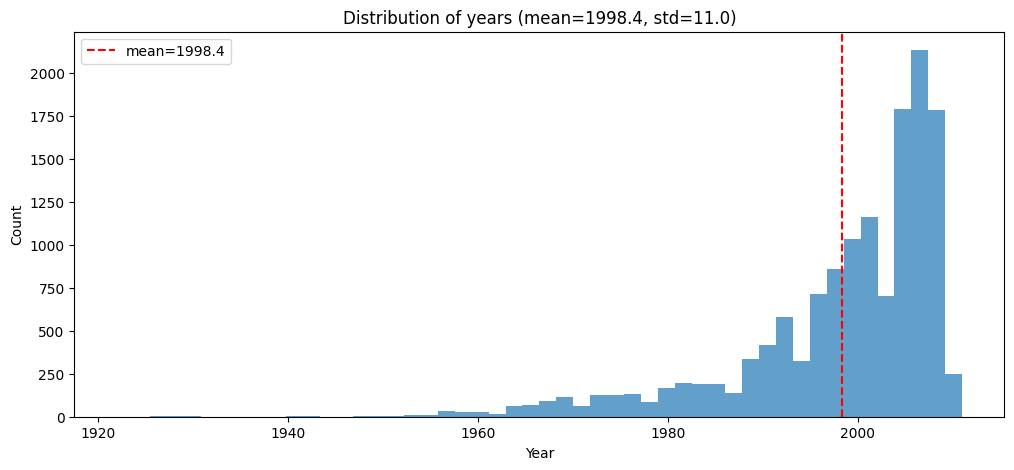

In [16]:
print("\nЦелевая переменная (year):")
print(f"  Mean: {y.mean():.2f}")
print(f"  Std:  {y.std():.2f}")
print(f"  Min:  {y.min()}")
print(f"  Max:  {y.max()}")
print(f"  Медиана: {np.median(y):.0f}")

# Распределение
plt.figure(figsize=(12, 5))
plt.hist(y, bins=50, alpha=0.7)
plt.xlabel("Year")
plt.ylabel("Count")
plt.title(f"Distribution of years (mean={y.mean():.1f}, std={y.std():.1f})")
plt.axvline(y.mean(), color='red', linestyle='--', label=f"mean={y.mean():.1f}")
plt.legend()
plt.show()

In [17]:
scaler = StandardScaler()
X_train_full = scaler.fit_transform(train_x.values)
X_test = scaler.transform(test_x.values)

print("X_train mean:", X_train_full.mean(axis=0).mean())
print("X_train std:", X_train_full.std(axis=0).mean())

X_train mean: -9.478132564514195e-18
X_train std: 1.0


In [18]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y, test_size=0.15, random_state=42
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}")

Train: (11900, 90), Val: (2100, 90)


In [19]:
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
y_val_scaled = y_scaler.transform(y_val.reshape(-1, 1)).flatten()

print(f"y_train_scaled: mean={y_train_scaled.mean():.4f}, std={y_train_scaled.std():.4f}")
print(f"y_train_scaled: min={y_train_scaled.min():.2f}, max={y_train_scaled.max():.2f}")

y_train_scaled: mean=0.0000, std=1.0000
y_train_scaled: min=-6.88, max=1.14


In [20]:
def to_tensor(x, y=None):
    x_t = torch.tensor(x, dtype=torch.float32)
    if y is not None:
        y_t = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
        return x_t, y_t
    return x_t

X_train_t, y_train_t = to_tensor(X_train, y_train_scaled)
X_val_t, y_val_t = to_tensor(X_val, y_val_scaled)
X_test_t = to_tensor(X_test)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=512, shuffle=False)

In [21]:
import torch

class AdamW:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.t = 0

        # состояния для каждого параметра
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue

                g = p.grad

                self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
                self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * (g ** 2)

                # Bias correction
                m_hat = self.m[i] / (1 - self.beta1 ** self.t)
                v_hat = self.v[i] / (1 - self.beta2 ** self.t)

                adaptive_step = m_hat / (v_hat.sqrt() + self.eps)

                p -= self.lr * adaptive_step
                p -= self.lr * self.weight_decay * p

In [22]:
class YearPredictor(nn.Module):
    def __init__(self, input_dim=90, hidden_dims=[256, 128, 64], dropout=0.3):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_dims:
            layers += [
                nn.Linear(prev_dim, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
            prev_dim = h
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [23]:
torch.manual_seed(42)
model = YearPredictor(input_dim=90, hidden_dims=[128, 64], dropout=0.5).to(device)

loss_fn = nn.MSELoss()
optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

epochs = 50
best_val_loss = float('inf')
best_state = None
history = {"train": [], "val": []}
patience = 2
no_improvement = 0

for epoch in range(epochs):
    # train
    model.train()
    train_loss, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x.size(0)
        n += x.size(0)
    train_loss /= n

    # val
    model.eval()
    val_loss, n = 0.0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            val_loss += loss_fn(model(x), y).item() * x.size(0)
            n += x.size(0)
    val_loss /= n

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        no_improvement = 0
    else:
        no_improvement += 1
        if no_improvement >= patience:
            print(f"Early stopping на эпохе {epoch+1}, best val = {best_val_loss:.4f}")
            break

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:2d}: train={train_loss:.4f}, val={val_loss:.4f}")

model.load_state_dict(best_state)
print(f"\nBest val MSE (scaled): {best_val_loss:.4f}")

Epoch  1: train=1.0465, val=0.8019
Epoch  5: train=0.7746, val=0.6928
Epoch 10: train=0.6986, val=0.6556
Epoch 15: train=0.6687, val=0.6464
Epoch 20: train=0.6574, val=0.6410
Epoch 25: train=0.6340, val=0.6328
Early stopping на эпохе 27, best val = 0.6328

Best val MSE (scaled): 0.6328


In [24]:
model.eval()
val_preds_scaled = []
val_targets_scaled = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        preds = model(x).cpu().numpy()
        val_preds_scaled.append(preds)
        val_targets_scaled.append(y.numpy())

val_preds_scaled = np.vstack(val_preds_scaled).flatten()
val_targets_scaled = np.vstack(val_targets_scaled).flatten()

val_preds = y_scaler.inverse_transform(val_preds_scaled.reshape(-1, 1)).flatten()
val_targets = y_scaler.inverse_transform(val_targets_scaled.reshape(-1, 1)).flatten()

real_mse = ((val_preds - val_targets) ** 2).mean()
print(f"Val MSE: {real_mse:.2f}")

Val MSE: 77.77


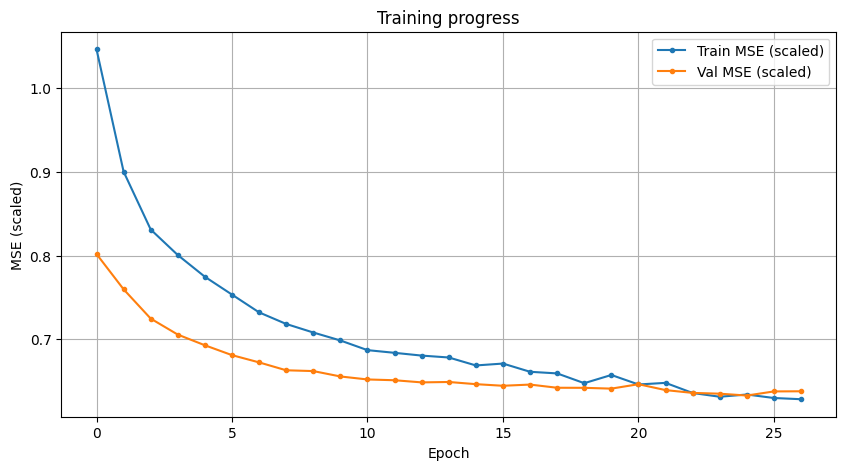

In [25]:
plt.figure(figsize=(10, 5))
plt.plot(history["train"], label="Train MSE (scaled)", marker='o', markersize=3)
plt.plot(history["val"], label="Val MSE (scaled)", marker='o', markersize=3)
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.title("Training progress")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
model.eval()
with torch.no_grad():
    X_test_t = X_test_t.to(device)
    preds_scaled = model(X_test_t).cpu().numpy().flatten()

preds = y_scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
preds = np.round(preds).astype(int)

submission = pd.DataFrame({
    "id": test_ids.values,
    "year": preds,
})
submission.to_csv("submission.csv", index=False)

print(submission.head())
print("\nСохранено в submission.csv")
print(f"Диапазон предсказаний: [{preds.min()}, {preds.max()}]")

      id  year
0   3416  2002
1  18991  2003
2  11105  1999
3  18902  2002
4  18958  2003

Сохранено в submission.csv
Диапазон предсказаний: [1976, 2008]


=== Мой AdamW ===
  Epoch  5: train=0.7746, val=0.6928
  Epoch 10: train=0.6986, val=0.6556
  Epoch 15: train=0.6687, val=0.6464
  Epoch 20: train=0.6574, val=0.6410
  Epoch 25: train=0.6340, val=0.6328
  Early stopping на эпохе 27

=== torch AdamW ===
  Epoch  5: train=0.7747, val=0.6927
  Epoch 10: train=0.6984, val=0.6558
  Epoch 15: train=0.6689, val=0.6453
  Epoch 20: train=0.6579, val=0.6395
  Epoch 25: train=0.6338, val=0.6340
  Early stopping на эпохе 27

Мой AdamW:    best val = 0.6328, эпох = 27
torch AdamW:  best val = 0.6340, эпох = 27


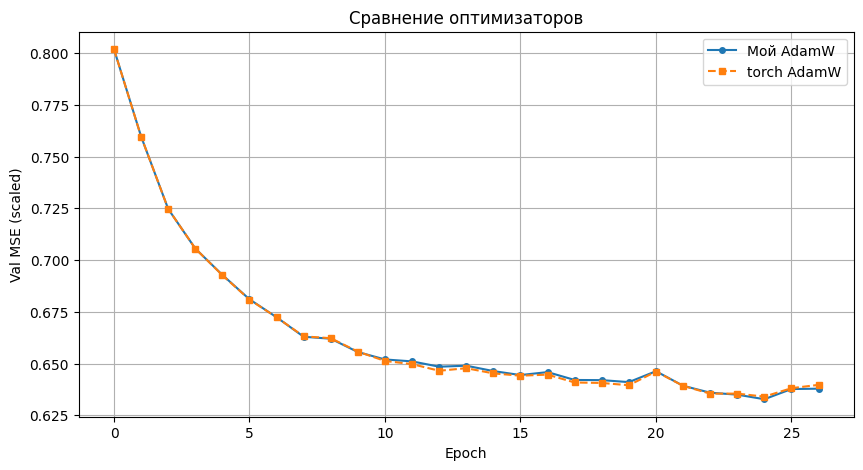

In [27]:
def train_with_early_stopping(model, optimizer, train_loader, val_loader,
                              epochs=100, patience=2, verbose=True):
    history = {"train": [], "val": []}
    best_val_loss = float('inf')
    best_state = None
    no_improvement = 0

    for epoch in range(epochs):
        model.train()
        tr_loss, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * x.size(0)
            n += x.size(0)
        tr_loss /= n

        model.eval()
        vl_loss, n = 0.0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                vl_loss += loss_fn(model(x), y).item() * x.size(0)
                n += x.size(0)
        vl_loss /= n

        history["train"].append(tr_loss)
        history["val"].append(vl_loss)

        if vl_loss < best_val_loss - 1e-4:
            best_val_loss = vl_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improvement = 0
        else:
            no_improvement += 1
            if no_improvement >= patience:
                if verbose:
                    print(f"  Early stopping на эпохе {epoch+1}")
                break

        if verbose and (epoch + 1) % 5 == 0:
            print(f"  Epoch {epoch+1:2d}: train={tr_loss:.4f}, val={vl_loss:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)

    return history, best_val_loss


print("=== Мой AdamW ===")
torch.manual_seed(42)
model_mine = YearPredictor(input_dim=90, hidden_dims=[128, 64], dropout=0.5).to(device)
opt_mine = AdamW(model_mine.parameters(), lr=1e-3, weight_decay=1e-4)
history_mine, best_mine = train_with_early_stopping(
    model_mine, opt_mine, train_loader, val_loader, epochs=100, patience=2
)

print("\n=== torch AdamW ===")
torch.manual_seed(42)
model_torch = YearPredictor(input_dim=90, hidden_dims=[128, 64], dropout=0.5).to(device)
opt_torch = torch.optim.AdamW(model_torch.parameters(), lr=1e-3, weight_decay=1e-4)
history_torch, best_torch = train_with_early_stopping(
    model_torch, opt_torch, train_loader, val_loader, epochs=100, patience=2
)

print(f"\nМой AdamW:    best val = {best_mine:.4f}, эпох = {len(history_mine['val'])}")
print(f"torch AdamW:  best val = {best_torch:.4f}, эпох = {len(history_torch['val'])}")

plt.figure(figsize=(10, 5))
plt.plot(history_mine["val"], label="Мой AdamW", marker='o', markersize=4)
plt.plot(history_torch["val"], label="torch AdamW", marker='s', markersize=4, linestyle='--')
plt.xlabel("Epoch")
plt.ylabel("Val MSE (scaled)")
plt.title("Сравнение оптимизаторов")
plt.legend()
plt.grid(True)
plt.show()